# Within-subject cross-session motor imagery decoding with EEGNet

##  Research question and evaluation protocol

 Can an EEGNet trained on the first session of a participant (BCI Competition IV-2a, 4 classes: left hand, right hand, feet, tongue) decode the second session of the *same* participant, recorded on another day? Does Gaussian augmentation applied to the training data only change this result?

**Protocol (one separate model per participant, 9 participants).**

| Set | Data | Use |
|---|---|---|
| Training | session `T`, acquisition runs 0–4 **used together** (240 trials) | weight updates |
| Validation | session `T`, acquisition run 5 (48 trials) | early stopping and checkpoint selection |
| Test | whole session `E` (288 trials) | final evaluation, **once**, after the checkpoint is frozen |

 An *acquisition run* is one of the 6 task runs of 48 trials recorded in a session (column `run` = 0…5 of the trial table written by the preprocessing notebook). A *model fit* is one training of an EEGNet for a given participant, condition and seed.

A **new EEGNet is created for every participant × condition × seed (one model fit), not for each acquisition run.** In each fit the five acquisition runs 0–4 of session `T` are concatenated and used **together** for training (240 trials), and acquisition run 5 of `T` is the validation set of that same fit. The model is randomly initialised; no pretrained model or checkpoint from another fit is ever loaded. Session `E` is used only for the final test.

This is not a LOSO experiment, not an evaluation on unseen people, and not a random split of trials pooled from the two sessions.

`NoAug` (standard EEGNet) and `Aug` (the same EEGNet with on-the-fly Gaussian noise on the training data only). Same trials, architecture, optimiser, hyper-parameters, early-stopping rule, seeds and shuffling order: only the noise differs.

A trial starts at t = 0 s (event 768) and the motor-imagery cue appears at t = 2 s (events 769–772 in session `T`, event 783 in session `E`); in the checked GDF files the distance is always 500 samples (2.000 s). The classification window is **0.5–3.5 s after the cue** (751 samples at 250 Hz) and is anchored directly on the cue events, not on an assumed offset. A C3/C4 lateralisation check on session `T` only (section 4) is used to see whether contralateral ERD appears after the cue. The procedure is offline: the paradigm timing is known.

Mean and standard deviation of each channel are estimated on a **pre-cue baseline** (the second of fixation before the cue, i.e. −1.0…0 s relative to the cue) and used to normalise the following classification window, so the statistics come only from samples that precede the window. This replaces the whole-window z-score used in earlier versions; results are not comparable with those.

**What is not done.** No hyper-parameter tuning, no other architecture, and no use of the test session to choose the pipeline, the epochs or the augmentation.

### Nature of the evaluation and what is estimated on which data

This is an **offline evaluation** that uses **offline run-wise preprocessing with calibration-only ICA**. The pipeline is **not certified as strictly causal** and is **not shown to be equivalent to a streaming implementation**. In particular, the minimum-phase FIR filter was applied offline with MNE's default padding, which does not by itself demonstrate causality at run edges. 

| Element | Training (T, runs 0–4) | Validation (T, run 5) | Test (E) | Uses class labels? |
|---|---|---|---|---|
| FIR filter 1–40 Hz | minimum-phase, offline, applied run by run, fixed parameters | same | same | no |
| ICA (decomposition of the 22 EEG channels) | fitted **only on the EOG-calibration runs of T**, then frozen | applied, **not part of the fit** | default: fitted on the calibration runs of E (unlabeled, recorded before the trials), then frozen; exploratory alternative: frozen matrix of T | no |
| Component selection | automatic correlation with the 3 EOG channels on the calibration runs | same | same, on the calibration runs of E (or of T) | no |
| Normalisation | pre-cue baseline (−1…0 s from the cue) of the single trial: only samples preceding the window | same | same | no |
| EEGNet weights | **updated here** | not used for updates | never | yes, as targets (T only) |
| BatchNorm statistics | accumulated here | inference mode | inference mode | no |
| Early stopping and checkpoint | no | **loss on run 5** | never | yes, as targets (T only) |
| Hyper-parameters, augmentation, window | fixed beforehand (not optimised on E); the window was only inspected on session T | same | same | no |

The labels of E are read only for consistency checks and to compute the final scores in `evaluate_test`, after the checkpoint is frozen. The model receives a single input of shape (22, 751, 1) containing only EEG channels: no events, class codes or metadata. The provenance file of every `.fif` is validated at every load.

**What remains not online.**
- The calibration runs of E belong to the test session: they are unlabeled and precede the trials, but the default ICA uses them. The `session_T_calibration` option avoids this.
- Windows are anchored on the known paradigm timing (cue), as in a synchronous BCI, and the model decides only after seeing the whole 3 s window.
- Architecture, band, window and hyper-parameters were chosen offline  without using E.
- The minimum-phase filter distorts the phase, and its behaviour at run edges was not demonstrated to be causal; results refer to this specific pipeline.

## 2. Imports and central configuration
**Frozen configuration.** The configuration is written to `frozen_experiment_config.json` (with its hash, library versions and the participants actually run) **before any data is loaded**. If it is later changed, the notebook refuses to continue. `BCI_SUBJECTS` (default: all nine participants) only selects the participants whose files are available; it does not change any other setting.

In [1]:
import os, json, time, random, platform, glob, hashlib, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import scipy.io as sio
from scipy.signal import hilbert, butter, sosfiltfilt
import matplotlib.pyplot as plt
import mne
import sklearn
import tensorflow as tf
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             cohen_kappa_score, precision_recall_fscore_support,
                             confusion_matrix)
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Dense, Activation, Dropout, Conv2D, AveragePooling2D,
                                     SeparableConv2D, DepthwiseConv2D, BatchNormalization,
                                     Flatten, Input)
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.optimizers import Adam

mne.set_log_level('ERROR')

EXPERIMENT_MODE = 'full'      # 'full' (frozen configuration) | 'smoke' (1 subject, 3 epochs: only to check that everything runs)

CFG = dict(
    experiment_mode=EXPERIMENT_MODE,
    # paths
    # output of 6_preprocessing_both_sessions.ipynb: one sub-directory per ICA_SOURCE_E setting (relative path)
    ica_source_E='own_calibration',    # MUST match the preprocessing notebook: 'own_calibration' | 'session_T_calibration' (exploratory)
    clean_base_dir=os.environ.get('BCI_CLEAN_DIR', 'cleaned_data_1_40_runwise'),
    clean_suffix='_runwise_clean_1_40_raw.fif',
    pipeline_version='runwise_calibration_ica_v3',
    out_root=os.environ.get('BCI_OUT_DIR', './results_cross_session'),
    # dataset constants
    fs=250,
    expected_ch_names=['Fz', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'C5', 'C3', 'C1', 'Cz', 'C2',
                       'C4', 'C6', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'P1', 'Pz', 'P2', 'POz'],
    eog_names=['EOG-left', 'EOG-central', 'EOG-right'],
    # explicit class mapping: BCI code (1..4) -> label (0..3)
    class_names=['left hand', 'right hand', 'feet', 'tongue'],
    bci_code_to_label={1: 0, 2: 1, 3: 2, 4: 3},
    # all times are relative to the CUE onset (GDF events 769-772 / 783), not to the trial start
    mi_start_after_cue_s=0.5, mi_end_after_cue_s=3.5,
    band_hz=(1.0, 40.0),               # already applied in the cleaned .fif files (offline, run-wise minimum-phase FIR)
    # normalisation: mean/std of each channel are estimated on a PRE-CUE baseline (samples preceding the window)
    normalization='baseline_pre_cue',  # 'baseline_pre_cue' (default) | 'trial_zscore' (legacy: statistics of the whole window, exploratory only)
    baseline_start_s=-1.0, baseline_end_s=0.0,  # seconds relative to the cue: the 1 s of fixation BEFORE the cue
    # split inside session 1: 'run' column of the trial table (0-based index among the 6 task runs)
    train_runs=[0, 1, 2, 3, 4], val_runs=[5],
    # training (starting configuration, not tuned)
    learning_rate=1e-3, batch_size=32, max_epochs=100, patience=15, dropout=0.5,
    aug_sigma=0.05, aug_prob=0.5,      # noise std in baseline-normalised units; prob. of noising each trial
    seeds=[0], conditions=['NoAug', 'Aug'],
    # default: all nine participants; BCI_SUBJECTS (e.g. '1,9') only selects the participants whose files are available
    subjects=[int(x) for x in os.environ.get('BCI_SUBJECTS', '1,2,3,4,5,6,7,8,9').split(',')],
    resume=True,                       # skip runs already saved on disk
)
if EXPERIMENT_MODE == 'smoke':
    CFG.update(subjects=[1], max_epochs=3, patience=3)

CFG['n_samples'] = int(round((CFG['mi_end_after_cue_s'] - CFG['mi_start_after_cue_s']) * CFG['fs'])) + 1  # inclusive ends
CFG['n_channels'] = len(CFG['expected_ch_names'])
assert CFG['ica_source_E'] in ('own_calibration', 'session_T_calibration')
CFG['clean_dir'] = str(Path(CFG['clean_base_dir']) / CFG['ica_source_E'])
# hash of everything that defines a training run: a saved run is reused only if this hash matches
CFG_HASH = hashlib.sha256(json.dumps({k: v for k, v in CFG.items() if k not in ('subjects', 'seeds', 'conditions', 'resume')},
                                     sort_keys=True, default=str).encode()).hexdigest()[:16]

OUT = Path(CFG['out_root']) / EXPERIMENT_MODE
# smoke/debug checkpoints are kept apart from final-evaluation checkpoints
DIRS = {k: OUT / k for k in ['metrics', 'predictions', 'history', 'trial_tables', 'figures']}
DIRS['checkpoints'] = OUT / ('checkpoints_dev' if EXPERIMENT_MODE == 'smoke' else 'checkpoints_final')
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

def set_all_seeds(seed):
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)

versions = dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__,
                pandas=pd.__version__, mne=mne.__version__, sklearn=sklearn.__version__,
                tensorflow=tf.__version__, keras=tf.keras.__version__)
(OUT / 'config.json').write_text(json.dumps(CFG, indent=2, default=str))
(OUT / 'versions.json').write_text(json.dumps(versions, indent=2))
print(json.dumps(versions, indent=2))

# ---- freeze the configuration BEFORE any data is loaded -------------------------------------------------------
FROZEN_FILE = OUT / 'frozen_experiment_config.json'
def freeze_configuration():
    """Write the configuration before loading any data; refuse to continue if it differs from an already frozen one."""
    payload = dict(experiment_mode=EXPERIMENT_MODE, cfg_hash=CFG_HASH, cfg=CFG, subjects_run=CFG['subjects'],
                   seeds=CFG['seeds'], conditions=CFG['conditions'], versions=versions,
                   frozen_at_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'))
    if FROZEN_FILE.exists():
        old = json.loads(FROZEN_FILE.read_text())
        assert old['cfg_hash'] == CFG_HASH, (f'the configuration differs from the one frozen in {FROZEN_FILE}. Results were produced '
                                             'under the frozen configuration; delete the file only to start a NEW, declared experiment.')
        print('configuration matches the frozen one (frozen at', old['frozen_at_utc'], ')')
    else:
        FROZEN_FILE.write_text(json.dumps(payload, indent=2, default=str))
        print('configuration frozen:', FROZEN_FILE, '| hash', CFG_HASH)
freeze_configuration()
print(f"mode={EXPERIMENT_MODE} | window {CFG['mi_start_after_cue_s']}-{CFG['mi_end_after_cue_s']} s after the cue "
      f"= {CFG['n_samples']} samples | outputs in {OUT}")

{
  "python": "3.12.7",
  "numpy": "2.2.5",
  "scipy": "1.15.3",
  "pandas": "2.3.0",
  "mne": "1.12.0",
  "sklearn": "1.7.2",
  "tensorflow": "2.20.0",
  "keras": "3.12.0"
}
configuration frozen: results_cross_session\full\frozen_experiment_config.json | hash b9a8e7bf09f96cb6
mode=full | window 0.5-3.5 s after the cue = 751 samples | outputs in results_cross_session\full


## 3. File, label and ICA quality-control audit

The audit lists which cleaned files exist for each participant and session (they are produced by `reprocessing_both_sessions.ipynb` from the GDF files). If session `E` is missing, the notebook says so and skips the final evaluation: it **never** replaces the test with session-1 data.

Labels of session `T` come from the GDF cue events (cross-checked with `true_labels/`); labels of session `E` come only from the official file `true_labels/A0xE.mat`, written into the trial table in the original order. If they are missing, the preprocessing stops: it never invents classes.

The **ICA quality-control report** below is read from the provenance files and keeps four things **separate**: (1) structure and fit data (calibration conditions and duration); (2) stability between seeds (a second fit on the same calibration data); (3) relation with the EOG channels (score of each excluded component with the EOG channels, from MNE's `find_bads_eog`); (4) quality of the reconstructed signal (retained RMS and EEG–EOG correlation before/after cleaning, on task runs not used for the fit). The ICA fit counter `n_iter/max_iter` is shown only as a record next to the MNE version recorded in the files and the one in use: on its own it does **not** identify why the algorithm stopped and does **not** certify the quality of the decomposition. Flags are descriptive (their thresholds are conventions, not tuned). The report is **never used to tune parameters or to choose seeds**, and nothing is chosen from session-`E` metrics. Flagged sessions (for example `A04T`, whose calibration block is shorter) should be inspected.

In [2]:
def session_paths(sid, session):
    """session: 'T' (first session) or 'E' (second session). All files come from the preprocessing notebook."""
    name = f'A{sid:02d}{session}'
    clean = Path(CFG['clean_dir'])
    return dict(
        name=name,
        fif=clean / f"{name}{CFG['clean_suffix']}",
        trials=clean / f'{name}_trials.csv',
        provenance=clean / f'{name}_provenance.json',
    )

rows = []
for sid in range(1, 10):
    for ses in ['T', 'E']:
        p = session_paths(sid, ses)
        rows.append(dict(subject=sid, session=ses, clean_fif=p['fif'].exists(), trial_table=p['trials'].exists(),
                         provenance=p['provenance'].exists()))
audit_files = pd.DataFrame(rows)
display(audit_files.pivot(index='subject', columns='session', values=['clean_fif', 'trial_table', 'provenance']))
missing_E = [s for s in CFG['subjects'] if not session_paths(s, 'E')['fif'].exists()]
print('Subjects selected:', CFG['subjects'])
print('Session E missing for:', missing_E if missing_E else 'none')

clean_fif       trial_table       provenance      
session         E     T           E     T          E     T
subject                                                   
1            True  True        True  True       True  True
2            True  True        True  True       True  True
3            True  True        True  True       True  True
4            True  True        True  True       True  True
5            True  True        True  True       True  True
6            True  True        True  True       True  True
7            True  True        True  True       True  True
8            True  True        True  True       True  True
9            True  True        True  True       True  True

Subjects selected: [1, 2, 3, 4, 5, 6, 7, 8, 9]
Session E missing for: none


In [3]:
qc_all = []
for sid in range(1, 10):
    for ses in ['T', 'E']:
        p = session_paths(sid, ses)
        if p['provenance'].exists():
            qc_all.append((sid, ses, json.loads(p['provenance'].read_text())))
print('MNE version recorded in the cleaned files:', sorted({p['mne_version'] for _, _, p in qc_all}), '| in use now:', mne.__version__)

def _q(p): return p['ica']['qc']
def _rs(p, k): return _q(p)['reconstructed_signal'][k]
t1 = pd.DataFrame([dict(subject=s, session=ss, calibration=_q(p)['structure']['calibration_conditions'],
                        calibration_total_s=_q(p)['structure']['calibration_total_s'], excluded=p['ica']['excluded_components'],
                        n_iter_record=f"{_q(p)['fit_counter']['n_iter']}/{_q(p)['fit_counter']['max_iter']}",
                        flags=_q(p)['flags']['structure']) for s, ss, p in qc_all])
t2 = pd.DataFrame([dict(subject=s, session=ss, median_abs_cosine=_q(p)['seed_stability']['median_abs_cosine'],
                        excluded_vs_second_seed=[(e['abs_cosine'], e['matched_also_excluded']) for e in _q(p)['seed_stability']['excluded_components']],
                        flags=_q(p)['flags']['seed_stability']) for s, ss, p in qc_all])
t3 = pd.DataFrame([dict(subject=s, session=ss,
                        abs_score_excluded=[(e['component'], e['max_abs_score']) for e in _q(p)['eog_relation']['excluded_components']],
                        max_abs_score_non_excluded=_q(p)['eog_relation']['max_abs_score_non_excluded'],
                        flags=_q(p)['flags']['eog_relation']) for s, ss, p in qc_all])
t4 = pd.DataFrame([dict(subject=s, session=ss,
                        task_rms_min_median=(_rs(p, 'task_runs')['rms_retained_ratio']['min'], _rs(p, 'task_runs')['rms_retained_ratio']['median']),
                        task_eog_corr_before_after=(_rs(p, 'task_runs')['mean_abs_corr_eeg_eog_before'], _rs(p, 'task_runs')['mean_abs_corr_eeg_eog_after']),
                        flags=_q(p)['flags']['reconstructed_signal']) for s, ss, p in qc_all])
for title, t, fn in [('1. Structure and fit data', t1, 'ica_qc_1_structure.csv'), ('2. Stability between seeds', t2, 'ica_qc_2_seed_stability.csv'),
                     ('3. Relation with the EOG channels (max |score| of each excluded component)', t3, 'ica_qc_3_eog_relation.csv'),
                     ('4. Reconstructed-signal quality (task runs, not used for the fit)', t4, 'ica_qc_4_signal_quality.csv')]:
    print(chr(10) + title); display(t); t.to_csv(OUT / fn, index=False)

MNE version recorded in the cleaned files: ['1.12.0'] | in use now: 1.12.0

1. Structure and fit data


,subject,session,calibration,calibration_total_s,excluded,n_iter_record,flags
0,1,T,"[eyes open, eyes closed, eye movements]",365.3,"[0, 3, 2]",500/500,[]
1,1,E,"[eyes open, eyes closed, eye movements]",423.2,"[0, 3]",500/500,[]
2,2,T,"[eyes open, eyes closed, eye movements]",383.9,"[1, 4, 2]",500/500,[]
3,2,E,"[eyes open, eyes closed, eye movements]",325.9,"[0, 4, 3]",500/500,[]
4,3,T,"[eyes open, eyes closed, eye movements]",317.3,"[2, 7]",500/500,[]
5,3,E,"[eyes open, eyes closed, eye movements]",270.2,"[1, 7]",500/500,[]
6,4,T,[eye movements],79.6,"[1, 0, 3]",500/500,[non_standard_calibration_structure]
7,4,E,"[eyes open, eyes closed, eye movements]",315.3,"[1, 0]",500/500,[]
8,5,T,"[eyes open, eyes closed, eye movements]",419.7,"[1, 2, 3]",121/500,[]
9,5,E,"[eyes open, eyes closed, eye movements]",394.6,"[0, 5, 2]",141/500,[]



2. Stability between seeds


,subject,session,median_abs_cosine,excluded_vs_second_seed,flags
0,1,T,0.999,"[(1.0, True), (1.0, True), (1.0, True)]",[]
1,1,E,0.981,"[(1.0, True), (1.0, True)]",[]
2,2,T,0.991,"[(1.0, True), (1.0, True), (1.0, True)]",[]
3,2,E,1.000,"[(1.0, True), (1.0, True), (1.0, True)]",[]
4,3,T,0.991,"[(1.0, True), (1.0, True)]",[]
5,3,E,0.997,"[(1.0, True), (1.0, True)]",[]
6,4,T,0.957,"[(1.0, True), (0.988, True), (0.961, False)]",[excluded_component_not_reproduced_with_second...
7,4,E,0.992,"[(1.0, True), (1.0, True)]",[]
8,5,T,0.949,"[(0.946, False), (1.0, True), (0.782, False)]",[excluded_component_not_reproduced_with_second...
9,5,E,0.991,"[(1.0, True), (1.0, True), (1.0, True)]",[]



3. Relation with the EOG channels (max |score| of each excluded component)


,subject,session,abs_score_excluded,max_abs_score_non_excluded,flags
0,1,T,"[(0, 0.733), (3, 0.729), (2, 0.134)]",0.068,[excluded_component_with_weak_abs_eog_score(<0...
1,1,E,"[(0, 0.808), (3, 0.772)]",0.113,[]
2,2,T,"[(1, 0.894), (4, 0.8), (2, 0.206)]",0.078,[excluded_component_with_weak_abs_eog_score(<0...
3,2,E,"[(0, 0.901), (4, 0.805), (3, 0.227)]",0.081,[excluded_component_with_weak_abs_eog_score(<0...
4,3,T,"[(2, 0.695), (7, 0.543)]",0.204,[]
5,3,E,"[(1, 0.786), (7, 0.579)]",0.107,[]
6,4,T,"[(1, 0.829), (0, 0.745), (3, 0.395)]",0.134,[]
7,4,E,"[(1, 0.797), (0, 0.686)]",0.085,[]
8,5,T,"[(1, 0.712), (2, 0.663), (3, 0.503)]",0.136,[]
9,5,E,"[(0, 0.742), (5, 0.63), (2, 0.629)]",0.179,[]



4. Reconstructed-signal quality (task runs, not used for the fit)


,subject,session,task_rms_min_median,task_eog_corr_before_after,flags
0,1,T,"(0.514, 0.798)","(0.1492, 0.0224)",[]
1,1,E,"(0.752, 0.943)","(0.1292, 0.0239)",[]
2,2,T,"(0.554, 0.926)","(0.2281, 0.0377)",[]
3,2,E,"(0.683, 0.899)","(0.0718, 0.076)",[eeg_eog_correlation_not_reduced_on_task_runs]
4,3,T,"(0.579, 0.886)","(0.0658, 0.0846)",[eeg_eog_correlation_not_reduced_on_task_runs]
5,3,E,"(0.86, 0.981)","(0.0475, 0.0242)",[]
6,4,T,"(0.786, 0.95)","(0.1395, 0.0247)",[]
7,4,E,"(0.474, 0.767)","(0.1675, 0.0494)",[a_channel_lost_more_than_half_of_its_rms_on_t...
8,5,T,"(0.686, 0.926)","(0.2123, 0.0808)",[]
9,5,E,"(0.782, 0.96)","(0.1267, 0.0483)",[]


## 4. Data loading and epoch traceability

For every session the loader:

1. reads the trial table written by the preprocessing notebook (cue position, run boundaries, label, artifact flag of every trial) and validates the provenance file;
2. reads the cleaned `.fif` signal (22 EEG channels only; EOG channels are excluded) and checks channel names and order;
3. checks that the cue annotations of the `.fif` coincide with the table (same samples and same classes);
4. **asserts** that the baseline and the classification window of every trial lie inside the correct run, and that all values are finite (no NaN/inf);
5. derives the number of channels and samples from the data and normalises each window with the mean and standard deviation of the **pre-cue baseline** of the same channel (−1.0…0 s relative to the cue), protected against division by zero; the baseline must end before the cue and before the window (checked with `assert`);
6. returns a **traceability table** with all original trials, including any that were excluded.

No filter is re-applied: the `.fif` files were already filtered 1–40 Hz (minimum-phase FIR, offline, run by run) and cleaned with the calibration-only ICA. The loader rejects files produced by a different pipeline or configuration. The `'trial_zscore'` normalisation of earlier versions stays selectable in `CFG` only as an exploratory analysis that uses the statistics of the whole window.

**Cleaning of sessions T and E.** The files `A0xT/E_runwise_clean_1_40_raw.fif` are produced by `6_preprocessing_both_sessions.ipynb`: run-wise minimum-phase filter, ICA fitted only on the calibration runs of each session and then frozen. For E the default uses the calibration runs of E (unlabeled, recorded before the test trials); the `session_T_calibration` alternative is an exploratory sensitivity analysis and must not be chosen from test performance. This is an offline evaluation; it is not equivalent to an online system.

In [4]:
EVENT_DESC = {1: 'left', 2: 'right', 3: 'foot', 4: 'tongue'}
DESC_TO_LABEL = {'left': 0, 'right': 1, 'foot': 2, 'tongue': 3}

def read_trial_table(p):
    """Trial table written by the preprocessing notebook: one row per trial, cue position, run, label, artifact flag."""
    df = pd.read_csv(p['trials'])
    assert len(df) == 288 and df['label_code'].isin([1, 2, 3, 4]).all()
    assert {'run', 'cue_sample', 'trial_start_sample', 'run_start_sample', 'run_end_sample'} <= set(df.columns)
    assert sorted(df['run'].unique()) == list(range(6)) and (df.groupby('run').size() == 48).all(), 'expected 6 task runs of 48 trials'
    assert (df['cue_sample'] - df['trial_start_sample'] == 500).all(), 'cue is not 500 samples after the trial start'
    df['label'] = df['label_code'].map(CFG['bci_code_to_label'])      # explicit mapping 1..4 -> 0..3
    assert df['label'].notna().all()
    return df

def check_provenance(p, session):
    """Refuse cleaned files produced by a different pipeline version or configuration."""
    if not Path(p['provenance']).exists():
        raise FileNotFoundError(f"{p['provenance']} not found: run 6_preprocessing_both_sessions.ipynb with the same "
                                f"ica_source_E setting ({CFG['ica_source_E']}); files from other pipelines are not accepted.")
    prov = json.loads(Path(p['provenance']).read_text())
    fp = prov['fingerprint']
    assert prov['pipeline_version'] == CFG['pipeline_version'], 'cleaned file comes from a different pipeline version'
    assert prov['session'] == session
    assert fp['ica_source_E_setting'] == CFG['ica_source_E'], 'files were produced with a different ica_source_E setting'
    assert tuple(fp['band_hz']) == tuple(CFG['band_hz']) and prov['filter']['phase'] == 'minimum'
    assert prov['calibration_events_verified'] is True
    assert prov['ica']['uses_task_runs_for_fit'] is False and prov['ica']['uses_labels'] is False
    return prov

def read_clean_eeg(fif_path):
    raw = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)
    ann = raw.annotations
    ev_mask = np.isin(ann.description, list(DESC_TO_LABEL))
    ann_samples = np.round(ann.onset[ev_mask] * raw.info['sfreq']).astype(int)
    ann_desc = np.asarray(ann.description)[ev_mask]
    raw.pick(['eeg'])                                           # drops the 3 EOG channels
    assert raw.ch_names == CFG['expected_ch_names'], f'Unexpected channel order: {raw.ch_names}'
    assert int(raw.info['sfreq']) == CFG['fs']
    return raw.get_data().astype(np.float64), ann_samples, ann_desc

def load_session(sid, session):
    """Epoch one session. Returns (X, y, meta) with X: (n_kept, 22, n_samples, 1).
    The window is defined relative to the CUE; labels are returned separately and are never part of X."""
    p = session_paths(sid, session)
    check_provenance(p, session)                                # refuse files made with a different pipeline/configuration
    meta = read_trial_table(p)
    assert (meta['session'] == session).all()
    eeg, ann_samples, ann_desc = read_clean_eeg(p['fif'])
    assert np.isfinite(eeg).all(), 'NaN/inf in the cleaned recording'

    # 1) cue annotations of the cleaned file must coincide with the trial table (same samples, same classes)
    order = np.argsort(ann_samples)
    ann_samples, ann_desc = ann_samples[order], ann_desc[order]
    assert np.array_equal(ann_samples, np.sort(meta['cue_sample'].values)), 'cue positions differ between .fif and trial table'
    assert np.array_equal(np.array([DESC_TO_LABEL[d] for d in ann_desc]),
                          meta.sort_values('cue_sample')['label'].values), 'labels differ between .fif and trial table'

    # 2) windowing relative to the cue
    fs = CFG['fs']
    start_off = int(round(CFG['mi_start_after_cue_s'] * fs))
    n_samp = CFG['n_samples']
    b0, b1 = int(round(CFG['baseline_start_s'] * fs)), int(round(CFG['baseline_end_s'] * fs))
    # the baseline must end at/before the cue and before the classification window starts
    assert CFG['baseline_end_s'] <= 0 and CFG['baseline_end_s'] <= CFG['mi_start_after_cue_s']
    # every baseline and window must lie INSIDE the correct run (run boundaries come from the trial table)
    assert (meta['cue_sample'] + b0 >= meta['run_start_sample']).all(), 'a baseline starts before its run'
    assert (meta['cue_sample'] + start_off + n_samp <= meta['run_end_sample']).all(), 'a window extends past its run'
    assert meta['run_end_sample'].max() <= eeg.shape[1]
    keep, reason, segs = [], [], []
    for cue in meta['cue_sample'].values:
        s0 = cue + start_off
        seg = eeg[:, s0:s0 + n_samp]
        base = eeg[:, cue + b0:cue + b1]                        # pre-cue fixation period (precedes the window)
        assert seg.shape[1] == n_samp and np.isfinite(seg).all() and np.isfinite(base).all()
        if (seg.std(axis=-1) < 1e-12).any() or (base.std(axis=-1) < 1e-12).any():
            keep.append(False); reason.append('flat channel'); continue
        if CFG['normalization'] == 'baseline_pre_cue':
            # per-channel mean/std come ONLY from samples that precede the classification window
            seg = (seg - base.mean(axis=-1, keepdims=True)) / (base.std(axis=-1, keepdims=True) + 1e-8)
        elif CFG['normalization'] == 'trial_zscore':
            # legacy: statistics of the whole window (includes its own later samples); exploratory only
            seg = (seg - seg.mean(axis=-1, keepdims=True)) / (seg.std(axis=-1, keepdims=True) + 1e-8)
        else:
            raise ValueError(CFG['normalization'])
        assert np.isfinite(seg).all()
        keep.append(True); reason.append(''); segs.append(seg)
    meta['kept'], meta['exclusion_reason'] = keep, reason
    meta['subject'], meta['session'] = sid, session
    meta['trial_id'] = [f'A{sid:02d}{session}_{i:03d}' for i in meta['trial_in_session']]

    X = np.stack(segs).astype(np.float32)
    assert np.isfinite(X).all()
    y = meta.loc[meta['kept'], 'label'].values.astype(np.int64)    # labels are returned separately: never part of X
    return X[..., np.newaxis], y, meta

def ensure_clean_file(sid, session):
    """Cleaned files are produced by the preprocessing notebook (6_preprocessing_both_sessions.ipynb)."""
    return session_paths(sid, session)['fif'].exists()

### Time-window check (session T only)

The cue is known from the GDF events. This check looks at whether the C3/C4 lateralisation (right hand minus left hand, 8–30 Hz) is larger after the cue (0–3 s) than in the 2 s of fixation before it. It uses **session `T` only** and never looks at the test session. It is an average check per participant: it does not guarantee that every single person shows the effect. The filter and the Hilbert envelope used here are non-causal on purpose, because this audit does not feed the model.

In [5]:
def lateralization_audit(sid, pre=(-2.0, 0.0), mi=(0.0, 3.0)):
    """Analysis-only check on session T, with times relative to the cue. Zero-phase filtering and the Hilbert envelope
    are non-causal on purpose here: this audit never feeds the model and is not part of the preprocessing pipeline."""
    p = session_paths(sid, 'T')
    meta = read_trial_table(p)
    eeg, _, _ = read_clean_eeg(p['fif'])
    i3, i4 = CFG['expected_ch_names'].index('C3'), CFG['expected_ch_names'].index('C4')
    sos = butter(4, [8, 30], btype='bandpass', fs=CFG['fs'], output='sos')
    pw = np.abs(hilbert(sosfiltfilt(sos, eeg[[i3, i4]], axis=-1), axis=-1)) ** 2
    def win_power(lo, hi):
        out = []
        for cue in meta['cue_sample'].values:
            a, b = cue + int(lo * CFG['fs']), cue + int(hi * CFG['fs'])
            out.append(pw[:, max(a, 0):b].mean(axis=1))
        return np.array(out)                                   # (n_trials, 2)
    def lat(lo, hi):
        w = win_power(lo, hi); f = lambda c: np.log(w[meta['label'].values == c, 0].mean() /
                                                    w[meta['label'].values == c, 1].mean())
        return f(1) - f(0)                                     # right minus left
    return dict(subject=sid, lat_pre_cue=lat(*pre), lat_mi=lat(*mi))

lat_table = pd.DataFrame([lateralization_audit(s) for s in CFG['subjects']])
display(lat_table.round(3))
print('Expected with the cue as reference: |lat_mi| larger than |lat_pre_cue| and negative (contralateral ERD after the cue).')

,subject,lat_pre_cue,lat_mi
0,1,-0.056,-0.271
1,2,0.018,-0.042
2,3,-0.097,-0.437
3,4,0.086,-0.133
4,5,-0.021,-0.008
5,6,0.040,-0.227
6,7,0.021,-0.125
7,8,-0.114,-0.094
8,9,-0.087,-0.319


Expected with the cue as reference: |lat_mi| larger than |lat_pre_cue| and negative (contralateral ERD after the cue).


In [6]:
SESSION_T = {}
for sid in CFG['subjects']:
    X, y, meta = load_session(sid, 'T')
    SESSION_T[sid] = (X, y, meta)
    meta.to_csv(DIRS['trial_tables'] / f'A{sid:02d}T_trials.csv', index=False)
    print(f"A{sid:02d}T: X={X.shape} | kept {meta['kept'].sum()}/{len(meta)} | "
          f"class counts {np.bincount(y, minlength=4).tolist()} | artifact-flagged trials kept: "
          f"{int(meta.loc[meta['kept'], 'artifact_flag'].sum())} | labels from {meta['label_source'].iloc[0]}")
    q = np.percentile(np.abs(X), [50, 99, 99.9, 100])
    print(f"      |x| after '{CFG['normalization']}' normalisation: median {q[0]:.2f}, p99 {q[1]:.1f}, p99.9 {q[2]:.1f}, max {q[3]:.1f}")

A01T: X=(288, 22, 751, 1) | kept 288/288 | class counts [72, 72, 72, 72] | artifact-flagged trials kept: 15 | labels from cue events 769-772 (verified against true_labels)
      |x| after 'baseline_pre_cue' normalisation: median 0.71, p99 3.0, p99.9 4.1, max 8.0
A02T: X=(288, 22, 751, 1) | kept 288/288 | class counts [72, 72, 72, 72] | artifact-flagged trials kept: 18 | labels from cue events 769-772 (verified against true_labels)
      |x| after 'baseline_pre_cue' normalisation: median 0.73, p99 3.1, p99.9 4.2, max 7.0
A03T: X=(288, 22, 751, 1) | kept 288/288 | class counts [72, 72, 72, 72] | artifact-flagged trials kept: 18 | labels from cue events 769-772 (verified against true_labels)
      |x| after 'baseline_pre_cue' normalisation: median 0.69, p99 2.9, p99.9 3.9, max 11.3
A04T: X=(288, 22, 751, 1) | kept 288/288 | class counts [72, 72, 72, 72] | artifact-flagged trials kept: 26 | labels from cue events 769-772 (verified against true_labels)
      |x| after 'baseline_pre_cue' nor

## 5. Training/validation split within the first session

The split is **by acquisition run, taken from the `run` column of the trial table**: runs 0–4 are used together for training and run 5 for validation (asserted); the model is not re-created per acquisition run. Runs are reconstructed from the run-start events (32766) of the GDF file, not invented. No trial appears in both sets, windows of different trials do not overlap in time (checked below), and the split is identical for all conditions and seeds. Only session `T` can enter the split (asserted).

Note: the ICA of session 1 is fitted only on the calibration runs, so neither the training runs nor the validation run enter its fit. The split by run remains chronological (run 5 follows runs 0–4).

In [7]:
def split_session1(X, y, meta):
    """Split session T by run, using the 'run' column of the trial table: runs 0-4 train, run 5 validation."""
    assert CFG['train_runs'] == [0, 1, 2, 3, 4] and CFG['val_runs'] == [5], 'split must be runs 0-4 (train) / run 5 (validation)'
    assert (meta['session'] == 'T').all(), 'only session T may enter training/validation'
    kept = meta[meta['kept']].reset_index(drop=True)
    tr = kept['run'].isin(CFG['train_runs']).values
    va = kept['run'].isin(CFG['val_runs']).values
    assert not (tr & va).any() and (tr | va).all()
    assert set(kept.loc[tr, 'run']) <= set(CFG['train_runs']) and set(kept.loc[va, 'run']) == {5}
    assert set(kept.loc[tr, 'trial_id']).isdisjoint(set(kept.loc[va, 'trial_id']))
    # windows of consecutive trials must not overlap
    onsets = np.sort(kept['cue_sample'].values)
    assert np.diff(onsets).min() >= CFG['n_samples'], 'overlapping windows'
    return dict(session='T', X_tr=X[tr], y_tr=y[tr], X_va=X[va], y_va=y[va],
                ids_tr=kept.loc[tr, 'trial_id'].tolist(), ids_va=kept.loc[va, 'trial_id'].tolist())

for sid in CFG['subjects']:
    sp = split_session1(*SESSION_T[sid])
    print(f"A{sid:02d}: train {len(sp['y_tr'])} {np.bincount(sp['y_tr'], minlength=4).tolist()} | "
          f"val {len(sp['y_va'])} {np.bincount(sp['y_va'], minlength=4).tolist()}")

A01: train 240 [60, 60, 60, 60] | val 48 [12, 12, 12, 12]
A02: train 240 [60, 60, 60, 60] | val 48 [12, 12, 12, 12]
A03: train 240 [60, 60, 60, 60] | val 48 [12, 12, 12, 12]
A04: train 240 [60, 60, 60, 60] | val 48 [12, 12, 12, 12]
A05: train 240 [60, 60, 60, 60] | val 48 [12, 12, 12, 12]
A06: train 240 [60, 60, 60, 60] | val 48 [12, 12, 12, 12]
A07: train 240 [60, 60, 60, 60] | val 48 [12, 12, 12, 12]
A08: train 240 [60, 60, 60, 60] | val 48 [12, 12, 12, 12]
A09: train 240 [60, 60, 60, 60] | val 48 [12, 12, 12, 12]


## 6. EEGNet model definition

EEGNet architecture in TensorFlow/Keras, unchanged from your earlier notebook (temporal kernel 64, depth multiplier 2, 16 separable filters, dropout 0.5, max-norm constraints). Input shape and number of classes are derived from the data; the output is softmax and the loss is `sparse_categorical_crossentropy` with integer labels 0–3.

In [8]:
def EEGNet_Model(nb_classes, Chans, Samples, dropoutRate=0.5):
    input1 = Input(shape=(Chans, Samples, 1))
    block1 = Conv2D(8, (1, 64), padding='same', use_bias=False)(input1)
    block1 = BatchNormalization()(block1)
    block1 = DepthwiseConv2D((Chans, 1), use_bias=False, depth_multiplier=2,
                             depthwise_constraint=max_norm(1.))(block1)
    block1 = BatchNormalization()(block1)
    block1 = Activation('elu')(block1)
    block1 = AveragePooling2D((1, 4))(block1)
    block1 = Dropout(dropoutRate)(block1)
    block2 = SeparableConv2D(16, (1, 16), use_bias=False, padding='same')(block1)
    block2 = BatchNormalization()(block2)
    block2 = Activation('elu')(block2)
    block2 = AveragePooling2D((1, 8))(block2)
    block2 = Dropout(dropoutRate)(block2)
    flatten = Flatten()(block2)
    dense = Dense(nb_classes, kernel_constraint=max_norm(0.25))(flatten)
    return Model(inputs=input1, outputs=Activation('softmax')(dense))

def build_model(chans, samples):
    m = EEGNet_Model(nb_classes=len(CFG['class_names']), Chans=chans, Samples=samples, dropoutRate=CFG['dropout'])
    m.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(learning_rate=CFG['learning_rate']),
              metrics=['accuracy'])
    return m

_m = build_model(CFG['n_channels'], CFG['n_samples'])
assert _m.output_shape == (None, 4)
print('input', _m.input_shape, '| output', _m.output_shape, '| parameters:', _m.count_params())
del _m

input (None, 22, 751, 1) | output (None, 4) | parameters: 3012


## 7. Training-only augmentation

The augmentation is **on-the-fly**: for each batch, every trial receives, with probability `aug_prob` (0.5), Gaussian noise `N(0, sigma²)` with `sigma = 0.05`, expressed in units of the baseline standard deviation (the signals are already baseline-normalised). The dataset is not duplicated, so both conditions have the same number of examples and of updates per epoch.

Randomness is separated: the **shuffle** uses one generator (seed `s`) that is identical in both conditions; the **noise** uses a second generator (seed `s + 10000`) that exists only in `Aug`. Validation and test data are never modified.

In [9]:
_Base = getattr(tf.keras.utils, 'PyDataset', tf.keras.utils.Sequence)

class TrainSequence(_Base):
    """Mini-batches with a fixed per-epoch shuffle; optional on-the-fly Gaussian noise (training only)."""
    def __init__(self, X, y, batch_size, sigma, prob, shuffle_seed, aug_seed):
        super().__init__()
        self.X, self.y, self.bs, self.sigma, self.prob = X, y, batch_size, sigma, prob
        self.rng_shuffle = np.random.default_rng(shuffle_seed)
        self.rng_aug = np.random.default_rng(aug_seed)
        self.order = self.rng_shuffle.permutation(len(y))
    def __len__(self):
        return int(np.ceil(len(self.y) / self.bs))
    def __getitem__(self, i):
        idx = self.order[i * self.bs:(i + 1) * self.bs]
        xb = self.X[idx].copy()
        if self.sigma > 0:
            noisy = self.rng_aug.random(len(idx)) < self.prob
            noise = self.rng_aug.normal(0.0, self.sigma, xb.shape).astype(np.float32)
            xb[noisy] += noise[noisy]
        return xb, self.y[idx]
    def on_epoch_end(self):
        self.order = self.rng_shuffle.permutation(len(self.y))

## 8. Training and checkpoint selection

For every participant × condition × seed (one *model fit*, not one per acquisition run), a **new model and optimiser** are created and randomly initialised with the same seed (so `NoAug` and `Aug` start from the same initial weights). No pretrained model is loaded; the only weights ever loaded are the best-validation checkpoint written by the same run (any stale checkpoint file is deleted before the fit and its creation time is asserted afterwards). Early stopping and checkpointing use only the **validation loss**. The result of every run is saved immediately, so work can be resumed after an interruption (`resume=True`); a saved fit is reused **only** if its configuration hash matches the current configuration.

Absolute determinism across different hardware and library versions is not guaranteed.

In [10]:
def class_counts(y):
    return np.bincount(y, minlength=len(CFG['class_names'])).tolist()

def classification_metrics(y_true, y_pred, prefix):
    labels = list(range(len(CFG['class_names'])))
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    out = {f'{prefix}_accuracy': accuracy_score(y_true, y_pred),
           f'{prefix}_balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
           f'{prefix}_macro_f1': f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0),
           f'{prefix}_kappa': cohen_kappa_score(y_true, y_pred, labels=labels),
           f'{prefix}_confusion': json.dumps(confusion_matrix(y_true, y_pred, labels=labels).tolist())}
    for i, name in enumerate(CFG['class_names']):
        k = name.replace(' ', '_')
        out[f'{prefix}_precision_{k}'], out[f'{prefix}_recall_{k}'], out[f'{prefix}_f1_{k}'] = p[i], r[i], f[i]
    return out

def run_id(sid, cond, seed):
    return f'A{sid:02d}_{cond}_seed{seed}'

def train_run(sid, cond, seed, split):
    """Train on session 1 only; return the model with the best-validation-loss weights restored."""
    assert split['session'] == 'T', 'training may only use session T'
    rid = run_id(sid, cond, seed)
    tf.keras.backend.clear_session()
    set_all_seeds(seed)                                   # same init for NoAug and Aug
    model = build_model(CFG['n_channels'], CFG['n_samples'])   # NEW randomly initialised EEGNet for this participant x condition x seed
    ckpt = DIRS['checkpoints'] / f'{rid}.weights.h5'
    if ckpt.exists():
        ckpt.unlink()                                     # never reuse a checkpoint written by an earlier fit
    seq = TrainSequence(split['X_tr'], split['y_tr'], CFG['batch_size'],
                        sigma=CFG['aug_sigma'] if cond == 'Aug' else 0.0, prob=CFG['aug_prob'],
                        shuffle_seed=seed, aug_seed=seed + 10_000)
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(str(ckpt), monitor='val_loss', save_best_only=True,
                                           save_weights_only=True),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=CFG['patience'],
                                         restore_best_weights=True),
    ]
    t0 = time.perf_counter(); t_wall = time.time()
    hist = model.fit(seq, epochs=CFG['max_epochs'], validation_data=(split['X_va'], split['y_va']),
                     callbacks=callbacks, verbose=0)
    train_time = time.perf_counter() - t0
    assert ckpt.exists() and ckpt.stat().st_mtime >= t_wall - 1, 'checkpoint was not written by this fit'
    model.load_weights(str(ckpt))                         # best checkpoint (by validation loss) written by THIS fit
    h = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
    info = dict(best_epoch=int(np.argmin(h['val_loss'])) + 1, best_val_loss=float(np.min(h['val_loss'])),
                epochs_run=len(h['loss']), train_time_s=train_time,
                optimizer_updates=len(h['loss']) * len(seq), n_params=model.count_params())
    (DIRS['history'] / f'{rid}.json').write_text(json.dumps(h))
    return model, info

## 9. Final second-session evaluation

Session `E` is loaded **only after** the checkpoint is frozen and it is never used for fitting. If the session-`E` files are not available, the run saves the validation metrics only and sets `test_available = False`: no test number is produced or substituted.

In [11]:
def evaluate_test(model, sid, cond, seed):
    """Evaluate the frozen model on the full second session. Returns (metrics, predictions) or (None, None)."""
    if not ensure_clean_file(sid, 'E'):                       # session E not preprocessed/available -> no test score
        return None, None
    X_te, y_te, meta_te = load_session(sid, 'E')           # session E is loaded only now, after the checkpoint is frozen
    assert (meta_te['session'] == 'E').all()
    meta_te.to_csv(DIRS['trial_tables'] / f'A{sid:02d}E_trials.csv', index=False)
    proba = model.predict(X_te, batch_size=64, verbose=0)
    y_pred = proba.argmax(axis=1)
    m = classification_metrics(y_te, y_pred, 'test')
    m.update(n_test=len(y_te), test_class_counts=json.dumps(class_counts(y_te)), test_available=True)
    pred = pd.DataFrame(dict(subject=sid, session='E', trial_id=meta_te.loc[meta_te['kept'], 'trial_id'].values,
                             condition=cond, seed=seed, true_label=y_te, pred_label=y_pred))
    for i, name in enumerate(CFG['class_names']):
        pred[f'proba_{name.replace(" ", "_")}'] = proba[:, i]
    return m, pred

def run_experiment(sid, cond, seed):
    rid = run_id(sid, cond, seed)
    f_metrics = DIRS['metrics'] / f'{rid}.csv'
    if CFG['resume'] and f_metrics.exists():
        saved_hash = pd.read_csv(f_metrics).get('config_hash', pd.Series([None])).iloc[0]
        if saved_hash == CFG_HASH:
            print(f'[skip] {rid} already done with the same configuration'); return
        print(f'[recompute] {rid}: saved fit was produced with a different configuration')
    X, y, meta = SESSION_T[sid]
    split = split_session1(X, y, meta)
    model, info = train_run(sid, cond, seed, split)
    pva = model.predict(split['X_va'], batch_size=64, verbose=0)
    row = dict(subject=sid, condition=cond, seed=seed, config_hash=CFG_HASH,
               n_train=len(split['y_tr']), n_val=len(split['y_va']),
               train_class_counts=json.dumps(class_counts(split['y_tr'])),
               val_class_counts=json.dumps(class_counts(split['y_va'])), **info)
    row.update(classification_metrics(split['y_va'], pva.argmax(axis=1), 'val'))
    m_test, pred = evaluate_test(model, sid, cond, seed)      # only after the checkpoint is frozen
    if m_test is None:
        row.update(test_available=False, n_test=0)
        print(f'[{rid}] session E not available -> test skipped')
    else:
        row.update(m_test)
        pred.to_csv(DIRS['predictions'] / f'{rid}.csv', index=False)
    pd.DataFrame([row]).to_csv(f_metrics, index=False)         # saved last: marks the run as complete
    print(f"[{rid}] best epoch {info['best_epoch']}/{info['epochs_run']} | val loss {info['best_val_loss']:.3f} | "
          f"val bal.acc {row['val_balanced_accuracy']:.3f}"
          + (f" | TEST bal.acc {row['test_balanced_accuracy']:.3f}" if row['test_available'] else ''))

In [12]:
# Main loop: participant x condition x seed (same seed list and same split for both conditions)
for sid in CFG['subjects']:
    for seed in CFG['seeds']:
        for cond in CFG['conditions']:
            run_experiment(sid, cond, seed)


[A01_NoAug_seed0] best epoch 71/86 | val loss 0.821 | val bal.acc 0.667 | TEST bal.acc 0.684
[A01_Aug_seed0] best epoch 71/86 | val loss 0.818 | val bal.acc 0.667 | TEST bal.acc 0.677
[A02_NoAug_seed0] best epoch 93/100 | val loss 1.156 | val bal.acc 0.542 | TEST bal.acc 0.465
[A02_Aug_seed0] best epoch 93/100 | val loss 1.158 | val bal.acc 0.542 | TEST bal.acc 0.469
[A03_NoAug_seed0] best epoch 97/100 | val loss 0.723 | val bal.acc 0.729 | TEST bal.acc 0.812
[A03_Aug_seed0] best epoch 97/100 | val loss 0.730 | val bal.acc 0.729 | TEST bal.acc 0.806
[A04_NoAug_seed0] best epoch 98/100 | val loss 0.877 | val bal.acc 0.729 | TEST bal.acc 0.451
[A04_Aug_seed0] best epoch 98/100 | val loss 0.878 | val bal.acc 0.729 | TEST bal.acc 0.444
[A05_NoAug_seed0] best epoch 63/78 | val loss 1.164 | val bal.acc 0.562 | TEST bal.acc 0.431
[A05_Aug_seed0] best epoch 63/78 | val loss 1.164 | val bal.acc 0.562 | TEST bal.acc 0.434
[A06_NoAug_seed0] best epoch 81/96 | val loss 0.993 | val bal.acc 0.562 |

## 10. Per-participant results

Results are read from the CSV files saved on disk. With several seeds, they are first averaged **within each participant**; participants are the statistical unit, never seeds or trials.

In [13]:
metrics_df = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(str(DIRS['metrics'] / '*.csv')))], ignore_index=True)
metrics_df.to_csv(OUT / 'all_metrics.csv', index=False)
TEST_COLS = ['test_accuracy', 'test_balanced_accuracy', 'test_macro_f1', 'test_kappa']
VAL_COLS = ['val_accuracy', 'val_balanced_accuracy', 'val_macro_f1', 'val_kappa']
RUN_COLS = ['subject', 'condition', 'seed', 'n_train', 'n_val', 'n_test', 'best_epoch', 'best_val_loss',
            'epochs_run', 'train_time_s', 'optimizer_updates', 'n_params']
print('Training / validation summary (session 1 only):')
display(metrics_df[RUN_COLS + VAL_COLS].round(3))
has_test = metrics_df['test_available'].fillna(False).astype(bool).any()
if has_test:
    test_df = metrics_df[metrics_df['test_available'].astype(bool)]
    per_subject = test_df.groupby(['subject', 'condition'])[TEST_COLS].mean().reset_index()  # seeds first
    display(per_subject.round(3))
else:
    print('\nNo session-E results available yet: add the A0xE files and re-run (resume=True keeps finished runs;'
          ' delete the corresponding files in metrics/ to re-evaluate them).')

Training / validation summary (session 1 only):


,subject,condition,seed,n_train,n_val,n_test,best_epoch,best_val_loss,epochs_run,train_time_s,optimizer_updates,n_params,val_accuracy,val_balanced_accuracy,val_macro_f1,val_kappa
0,1,Aug,0,240,48,288,71,0.818,86,44.399,688,3012,0.667,0.667,0.617,0.556
1,1,NoAug,0,240,48,288,71,0.821,86,45.330,688,3012,0.667,0.667,0.617,0.556
2,2,Aug,0,240,48,288,93,1.158,100,52.497,800,3012,0.542,0.542,0.543,0.389
3,2,NoAug,0,240,48,288,93,1.156,100,48.755,800,3012,0.542,0.542,0.543,0.389
4,3,Aug,0,240,48,288,97,0.730,100,52.240,800,3012,0.729,0.729,0.724,0.639
5,3,NoAug,0,240,48,288,97,0.723,100,75.438,800,3012,0.729,0.729,0.724,0.639
6,4,Aug,0,240,48,288,98,0.878,100,50.387,800,3012,0.729,0.729,0.730,0.639
7,4,NoAug,0,240,48,288,98,0.877,100,49.480,800,3012,0.729,0.729,0.730,0.639
8,5,Aug,0,240,48,288,63,1.164,78,38.846,624,3012,0.562,0.562,0.564,0.417
9,5,NoAug,0,240,48,288,63,1.164,78,38.240,624,3012,0.562,0.562,0.564,0.417


,subject,condition,test_accuracy,test_balanced_accuracy,test_macro_f1,test_kappa
0,1,Aug,0.677,0.677,0.668,0.569
1,1,NoAug,0.684,0.684,0.675,0.579
2,2,Aug,0.469,0.469,0.462,0.292
3,2,NoAug,0.465,0.465,0.458,0.287
4,3,Aug,0.806,0.806,0.804,0.741
5,3,NoAug,0.812,0.812,0.810,0.750
6,4,Aug,0.444,0.444,0.437,0.259
7,4,NoAug,0.451,0.451,0.445,0.269
8,5,Aug,0.434,0.434,0.432,0.245
9,5,NoAug,0.431,0.431,0.429,0.241


## 11. Aggregate and paired analyses

- **Unweighted mean across participants** (standard deviation with `ddof=1`, n = number of participants): every person weighs the same.
- **Metrics on pooled predictions**: all test predictions together; participants with more trials weigh more (here all have 288 trials, but the two numbers remain conceptually different).
- **Paired Aug − NoAug comparison** per participant, descriptive only: no significance test and no confidence interval computed on dependent scores. The chance level with 4 balanced classes is 0.25, but exceeding it is not the same as a "statistically significant" result.

Unweighted mean +/- std across participants (n = 9):


test_accuracy        test_balanced_accuracy        test_macro_f1  \
                   mean    std                   mean    std          mean   
condition                                                                    
Aug               0.561  0.134                  0.561  0.134         0.557   
NoAug             0.561  0.136                  0.561  0.136         0.557   

                 test_kappa         
             std       mean    std  
condition                           
Aug        0.133      0.415  0.178  
NoAug      0.136      0.415  0.182

Paired differences Aug - NoAug per participant (descriptive):


,delta_test_accuracy,delta_test_balanced_accuracy,delta_test_macro_f1,delta_test_kappa
subject,,,,
1,-0.007,-0.007,-0.007,-0.009
2,0.003,0.003,0.004,0.005
3,-0.007,-0.007,-0.007,-0.009
4,-0.007,-0.007,-0.008,-0.009
5,0.003,0.003,0.003,0.005
6,0.000,0.000,-0.000,0.000
7,0.003,0.003,0.004,0.005
8,0.010,0.010,0.010,0.014
9,0.000,-0.000,0.002,0.000


Metrics on pooled predictions (differ from the unweighted participant mean):


,condition,n_predictions,accuracy,balanced_accuracy,macro_f1
0,Aug,2592,0.561,0.561,0.562
1,NoAug,2592,0.561,0.561,0.562


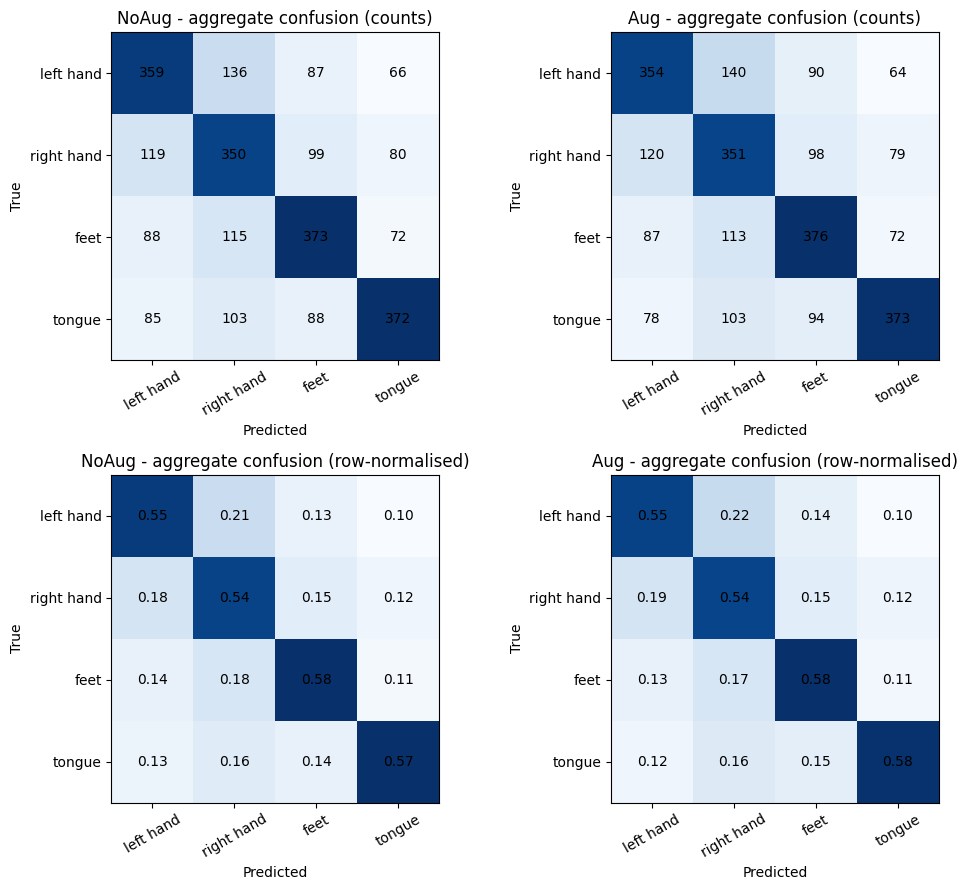

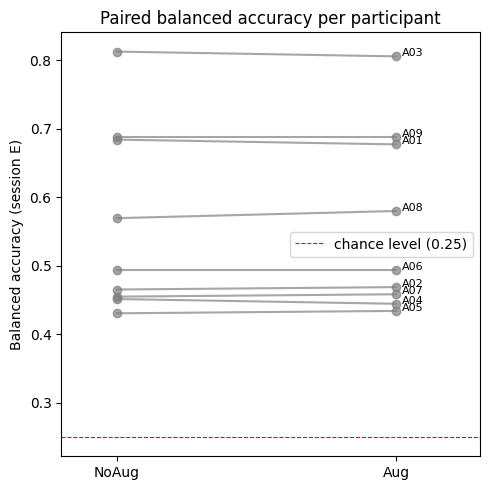

In [14]:
if has_test:
    summary = per_subject.groupby('condition')[TEST_COLS].agg(['mean', 'std'])
    print('Unweighted mean +/- std across participants (n = %d):' % per_subject['subject'].nunique())
    display(summary.round(3))

    paired = per_subject.pivot(index='subject', columns='condition', values=TEST_COLS)
    delta = pd.DataFrame({m: paired[m]['Aug'] - paired[m]['NoAug'] for m in TEST_COLS
                          if {'Aug', 'NoAug'} <= set(paired[m].columns)})
    delta.columns = [f'delta_{c}' for c in delta.columns]
    print('Paired differences Aug - NoAug per participant (descriptive):')
    display(delta.round(3))
    delta.to_csv(OUT / 'paired_differences.csv')

    # metrics on pooled predictions
    pred_all = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(str(DIRS['predictions'] / '*.csv')))], ignore_index=True)
    pooled = []
    for cond, g in pred_all.groupby('condition'):
        pooled.append(dict(condition=cond, n_predictions=len(g),
                           accuracy=accuracy_score(g.true_label, g.pred_label),
                           balanced_accuracy=balanced_accuracy_score(g.true_label, g.pred_label),
                           macro_f1=f1_score(g.true_label, g.pred_label, average='macro')))
    print('Metrics on pooled predictions (differ from the unweighted participant mean):')
    display(pd.DataFrame(pooled).round(3))

    # aggregate confusion matrices (counts and row-normalised)
    labels = list(range(4))
    fig, axes = plt.subplots(2, len(CFG['conditions']), figsize=(5.2 * len(CFG['conditions']), 9), squeeze=False)
    for j, cond in enumerate(CFG['conditions']):
        g = pred_all[pred_all.condition == cond]
        cm = confusion_matrix(g.true_label, g.pred_label, labels=labels)
        cmn = cm / cm.sum(axis=1, keepdims=True)
        for i, (mat, title, fmt) in enumerate([(cm, 'counts', '{:d}'), (cmn, 'row-normalised', '{:.2f}')]):
            ax = axes[i, j]; ax.imshow(mat, cmap='Blues')
            for a in range(4):
                for b in range(4):
                    ax.text(b, a, fmt.format(mat[a, b]), ha='center', va='center')
            ax.set_xticks(labels); ax.set_yticks(labels)
            ax.set_xticklabels(CFG['class_names'], rotation=30); ax.set_yticklabels(CFG['class_names'])
            ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{cond} - aggregate confusion ({title})')
    plt.tight_layout(); plt.savefig(DIRS['figures'] / 'confusion_aggregate.png', dpi=200); plt.show()

    # paired plot of balanced accuracy
    if {'Aug', 'NoAug'} <= set(paired['test_balanced_accuracy'].columns):
        fig, ax = plt.subplots(figsize=(5, 5))
        for sid, r in paired['test_balanced_accuracy'].iterrows():
            ax.plot([0, 1], [r['NoAug'], r['Aug']], marker='o', color='gray', alpha=0.7)
            ax.annotate(f'A{sid:02d}', (1.02, r['Aug']), fontsize=8)
        ax.axhline(0.25, color='r', ls='--', lw=0.8, label='chance level (0.25)')
        ax.set_xticks([0, 1]); ax.set_xticklabels(['NoAug', 'Aug']); ax.set_xlim(-0.2, 1.3)
        ax.set_ylabel('Balanced accuracy (session E)'); ax.set_title('Paired balanced accuracy per participant')
        ax.legend(); plt.tight_layout(); plt.savefig(DIRS['figures'] / 'paired_balanced_accuracy.png', dpi=200); plt.show()
else:
    print('Aggregate analyses skipped: no session-E results yet.')

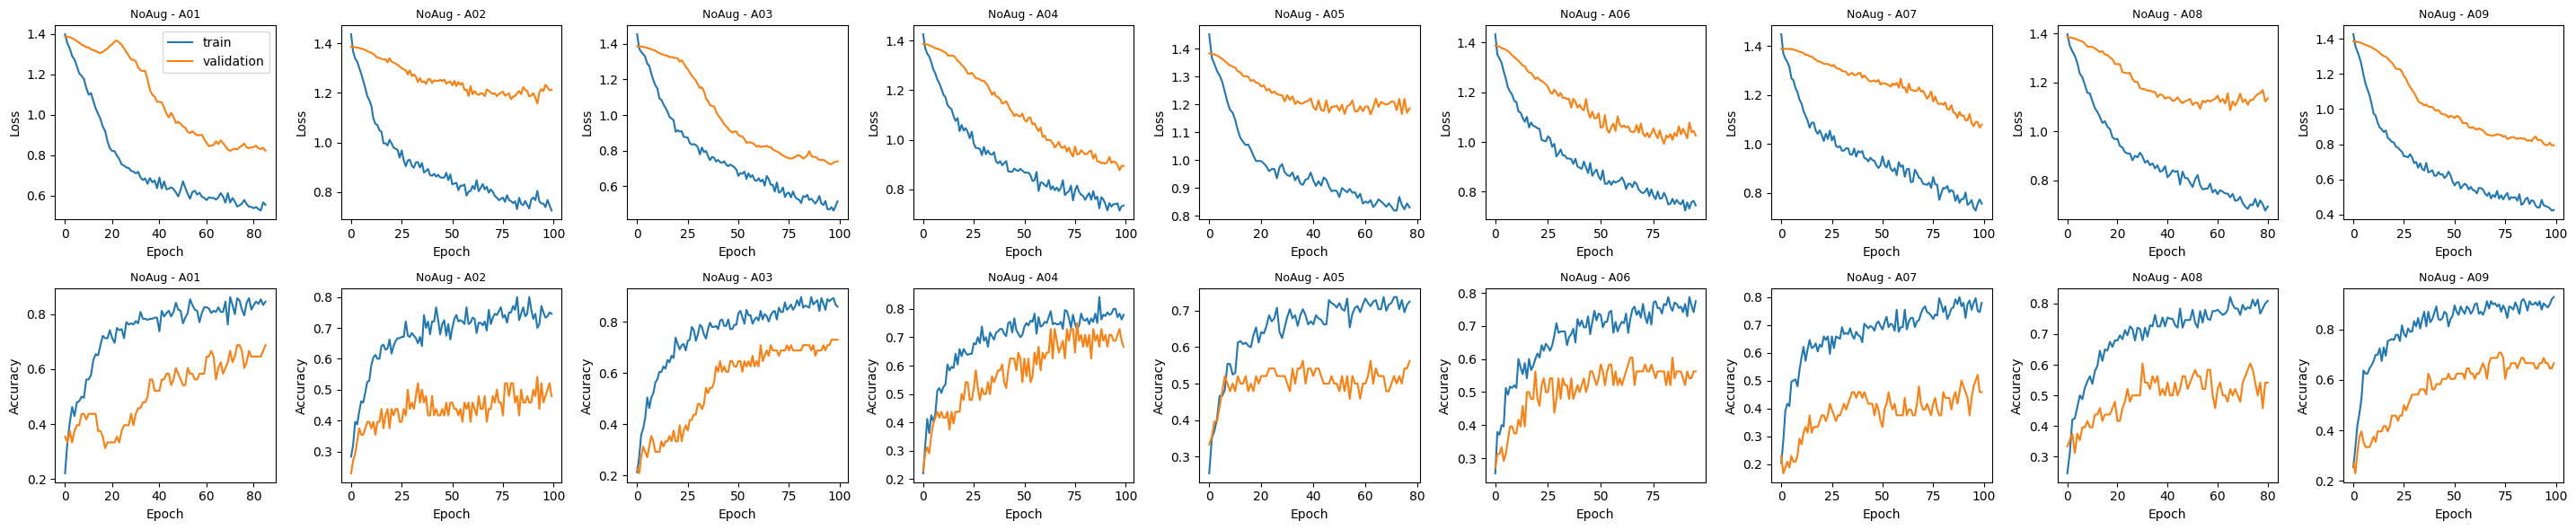

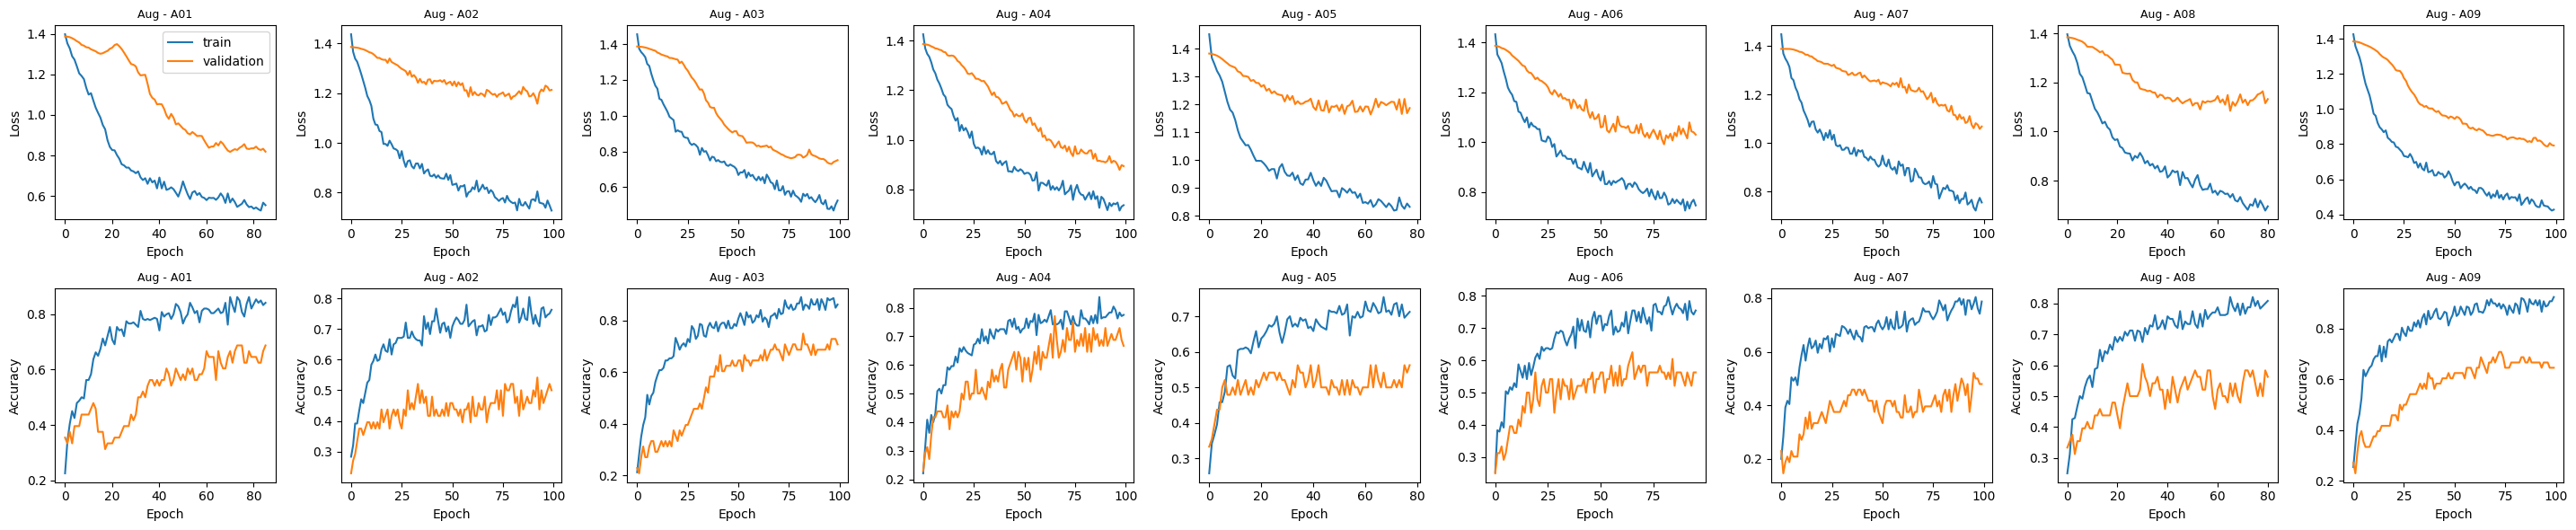

In [15]:
# Training/validation curves (first seed of the list) - available even without session E
seed0 = CFG['seeds'][0]
for cond in CFG['conditions']:
    subs = CFG['subjects']
    fig, axes = plt.subplots(2, len(subs), figsize=(3.2 * len(subs), 6), squeeze=False)
    for j, sid in enumerate(subs):
        f = DIRS['history'] / f'{run_id(sid, cond, seed0)}.json'
        if not f.exists():
            continue
        h = json.loads(f.read_text())
        for i, (k, lab) in enumerate([('loss', 'Loss'), ('accuracy', 'Accuracy')]):
            axes[i, j].plot(h[k], label='train'); axes[i, j].plot(h['val_' + k], label='validation')
            axes[i, j].set_title(f'{cond} - A{sid:02d}', fontsize=9); axes[i, j].set_xlabel('Epoch'); axes[i, j].set_ylabel(lab)
    axes[0, 0].legend(); plt.tight_layout()
    plt.savefig(DIRS['figures'] / f'curves_{cond}.png', dpi=200); plt.show()

In [16]:
# Report of excluded trials and data checks
tt = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(str(DIRS['trial_tables'] / '*.csv')))], ignore_index=True)
report = (tt.groupby(['subject', 'session'])
            .agg(n_trials=('trial_id', 'size'), n_kept=('kept', 'sum'),
                 n_excluded=('kept', lambda s: int((~s).sum())),
                 n_artifact_flagged=('artifact_flag', 'sum'),
                 label_source=('label_source', 'first')).reset_index())
display(report)
report.to_csv(OUT / 'data_checks_report.csv', index=False)

,subject,session,n_trials,n_kept,n_excluded,n_artifact_flagged,label_source
0,1,E,288,288,0,7,true_labels file
1,1,T,288,288,0,15,cue events 769-772 (verified against true_labels)
2,2,E,288,288,0,5,true_labels file
3,2,T,288,288,0,18,cue events 769-772 (verified against true_labels)
4,3,E,288,288,0,15,true_labels file
5,3,T,288,288,0,18,cue events 769-772 (verified against true_labels)
6,4,E,288,288,0,60,true_labels file
7,4,T,288,288,0,26,cue events 769-772 (verified against true_labels)
8,5,E,288,288,0,12,true_labels file
9,5,T,288,288,0,26,cue events 769-772 (verified against true_labels)


## Conclusions

**Limitations**
- Offline experiment on a public dataset: it does not demonstrate clinical or online operation.
- It does not demonstrate generalisation to new people: each model only sees its own participant.
- The test session must not influence the choice of the pipeline; any analysis performed after looking at test results must be declared **exploratory**.
- Preprocessing is **offline and run-wise with calibration-only ICA** (minimum-phase FIR filter applied run by run with MNE's default padding, ICA fitted only on the EOG-calibration runs and then frozen, pre-cue baseline normalisation). It is **not certified as strictly causal** and not shown to match a streaming implementation, and the evaluation is not a real-time test. The calibration runs of E belong to the test session (unlabeled, recorded before the trials); windows are anchored on the known paradigm timing; architecture and hyper-parameters were chosen offline.
- Cleaning with calibration data only may remove fewer artifacts than an ICA fitted on the whole recording; this must be checked per participant using the ICA quality-control report (calibration duration, excluded components, seed stability, flags). Sessions with a short or non-standard calibration block (e.g. `A04T`) need particular attention. No parameter was chosen from these checks or from session-`E` metrics.
- The validation set is a single run of 48 trials: checkpoint selection is noisy.
- With a single seed the variability due to initialisation is not estimated; with 9 participants the Aug–NoAug comparison remains descriptive.
- Predictions must not be attributed to Mu/Beta rhythms without dedicated analyses.
- The GDF files and labels follow the official dataset description; any deviation stops the preprocessing with an explicit assertion.

**Summary**

Both the augmented (`Aug`) and unaugmented (`NoAug`) configurations achieved the exact same mean test accuracy and mean balanced accuracy across the 9 participants: **0.561 ± 0.134** for `Aug` vs. **0.561 ± 0.136** for `NoAug`. 
 
  The overall Cohen's Kappa follows an identical negligible trend (**0.414 ± 0.179** for `Aug` vs. **0.414 ± 0.181** for `NoAug`). Since Kappa normalizes performance against the probability of random guessing (where 0.0 is chance and 1.0 is perfect agreement), a mean value around 0.41 confirms a moderate but stable decoding agreement across days. The net zero shift in Kappa demonstrates that Gaussian noise injection fails to alter the classification boundary or mitigate the temporal domain shifts inherent to cross-session EEG data.

A per-subject analysis highlights a completely inconsistent and marginal behavior, with the mean paired difference in balanced accuracy resting at **0.000 ± 0.006**:

| Subject | NoAug Accuracy | Aug Accuracy | Delta (Balanced Accuracy) | Cohen's Kappa (NoAug / Aug) | Effect of Augmentation |
|:---:|:---:|:---:|:---:|:---:|:---:|
| **Subject 1** | 0.6840 | 0.6771 | -0.0069 | 0.5787 / 0.5694 | Slight Drop |
| **Subject 2** | 0.4653 | 0.4688 | +0.0035 | 0.2870 / 0.2917 |  Marginal Gain |
| **Subject 3** | 0.8125 | 0.8056 | -0.0069 | 0.7500 / 0.7407 |  Slight Drop |
| **Subject 4** | 0.4514 | 0.4444 | -0.0069 | 0.2685 / 0.2593 | Slight Drop |
| **Subject 5** | 0.4306 | 0.4340 | +0.0035 | 0.2407 / 0.2454 |  Marginal Gain |
| **Subject 6** | 0.4931 | 0.4931 |  0.0000 | 0.3240 / 0.3241 |  Unchanged |
| **Subject 7** | 0.4549 | 0.4583 | +0.0035 | 0.2731 / 0.2778 |  Marginal Gain |
| **Subject 8** | 0.5694 | 0.5799 | +0.0104 | 0.4259 / 0.4398 |  Marginal Gain |
| **Subject 9** | 0.6875 | 0.6875 |  0.0000 | 0.6032 / 0.6032 | Unchanged |


**Next steps**

The introduction of training-only Gaussian noise leaves the final cross-session test evaluation on Session E statistically unchanged. Because looking strictly at performance outputs cannot explain *why* the network remains indifferent to this regularization, **next step transitions to a dedicated interpretability analysis**.



Thr upcoming analysis is strictly descriptive and structured around **four pre-planned benchmarks**:
1. **Frequency Perturbation (FFT Band-Stop):** removing core sensorimotor band mu (8–12 Hz),beta (13–30 Hz), and (mu+beta) directly from the test windows (and baseline configurations) to check if the network depends on these spectral ranges *more than on designated control bands*.
2. **Channel Ooclusion:** ìsolating spatial importance by setting core sensors (`C3`, `Cz`, `C4`) and the 17 sensorimotor channels to baseline levels, benchmarking their performance drops against non-sensorimotor controls and random channel subsets.
3. **Physiological ground truth (ERD/ERS Maps):** independent of the model,I will compute the raw band-power relative to the pre-cue baseline to verify if the expected contralateral (mu)(beta) desynchronization is physically present in the cleaned EEG data.
4. **Class-by-Class neurophysiological alignment:**  will cross-reference per-class recall and confusion patterns with the localized ERD maps to evaluate if the model's errors align logically with the physiological lateralization of the participant.
